# Gait Analysis

This notebook creates rollouts and performs and plots gait analysis on them

## Imports

In [12]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
# Change this to egl or glfw if available
os.environ["MUJOCO_GL"] = "egl"
import mediapy as media

from track_mjx.agent import checkpointing
from track_mjx.analysis import rollout

import jax
from jax import numpy as jp
import numpy as np
import mujoco
from mujoco import mjx
import matplotlib.pyplot as plt
import jax.numpy as jnp
import functools
from brax.envs.base import Env
from track_mjx.environment import wrappers
from typing import Callable, Dict
from omegaconf import DictConfig
from scipy import interpolate
from scipy.signal import medfilt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="deduperreload")

import matplotlib as mpl
%matplotlib inline
%config InlineBackend.figure_format='retina'

mpl.rcParams["figure.facecolor"] = "w"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600
mpl.rcParams["savefig.transparent"] = True
# mpl.rcParams["savefig.bbox_inches"] = "tight"
mpl.rcParams["font.size"] = 8
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Imitation Learning env setup

In [13]:
ckpt_path = "/root/vast/scott-yang/MIMIC-MJX/rodent-analysis/251006_144548_202519"
ckpt = checkpointing.load_checkpoint_for_eval(ckpt_path, step=99)
cfg = ckpt["cfg"]

cfg["data_path"] = "/root/vast/scott-yang/track-mjx/data/transform_snips.h5"

env = rollout.create_environment(cfg)
inference_fn = checkpointing.load_inference_fn(cfg, ckpt["policy"])

Loading checkpoint from /root/vast/scott-yang/MIMIC-MJX/rodent-analysis/251006_144548_202519 at step 99
Converting to torque actuators
Rescaling body tree with scale factor 0.9


## Generate rollouts

In [14]:
def create_rollout_generator(
    cfg: Dict | DictConfig,
    environment: Env,
    inference_fn: Callable,
):

    env = wrappers.RenderRolloutWrapperMulticlipTracking(environment)

    jit_inference_fn = jax.jit(inference_fn)
    jit_reset, jit_step = jax.jit(env.reset), jax.jit(env.step)

    clip_length = cfg["reference_config"].clip_length

    def generate_rollouts(clip_idx: int):
        """JAX-compatible rollout generation using jax.lax.scan."""
        rng = jax.random.PRNGKey(2)
        rng, reset_rng = jax.random.split(rng)
        reset_state = jit_reset(reset_rng, clip_idx=clip_idx)

        num_steps = env._steps_for_cur_frame * clip_length - 1

        def step_fn(carry, _):
            """Single step function for jax.lax.scan."""
            state, rng_key = carry
            act_rng, new_rng = jax.random.split(rng_key)
            ctrl, info = jit_inference_fn(state.obs, act_rng)
            next_state = jit_step(state, ctrl)

            # Return (new_carry, outputs)
            return (next_state, new_rng), (next_state, info)

        # Use jax.lax.scan instead of Python loop
        init_carry = (reset_state, rng)
        (final_state, final_rng), (states, network_infos) = jax.lax.scan(
            step_fn, init_carry, None, length=num_steps
        )

        # Prepend the initial state to get complete trajectory
        def prepend_state(init, trajectory):
            if trajectory.ndim == 0:  # Handle scalar values
                return trajectory
            return jnp.concatenate([init[None], trajectory])

        complete_rollout = jax.tree.map(prepend_state, reset_state, states)

        # Get reference trajectory
        ref_traj = env._get_reference_clip(reset_state.info)
        qposes_ref = jnp.repeat(
            jnp.hstack([ref_traj.position, ref_traj.quaternion, ref_traj.joints]),
            int(env._steps_for_cur_frame),
            axis=0,
        )

        return (complete_rollout, qposes_ref)

    return generate_rollouts

In [15]:
generate_rollouts = create_rollout_generator(cfg, env, inference_fn)

# Create a partial function with clip_length fixed
generate_rollouts_with_length = functools.partial(generate_rollouts)

jit_vmap_generate_rollout = jax.jit(jax.vmap(generate_rollouts_with_length))

In [16]:
# All clips which contain walking behaviour
clip_idxs = jp.array(
    [
        2,
        8,
        15,
        19,
        22,
        25,
        30,
        32,
        33,
        34,
        35,
        38,
        41,
        42,
        43,
        49,
        51,
        52,
        54,
        56,
        58,
        61,
        67,
        70,
        73,
        75,
    ]
)  # , 76, 82, 83, 96, 97, 98, 102, 104, 105, 107, 109, 110, 111, 112, 116, 117, 122, 123, 124, 125, 129, 131, 139, 140, 143, 144, 145, 148, 149, 150, 152, 155, 156, 162, 163, 167, 169, 170, 171, 174, 176, 178, 179, 182, 184, 188, 189, 190, 191, 196, 197, 198, 201, 206, 209, 211, 212, 213, 215, 216, 219, 220, 224, 226, 230, 231, 232, 235, 238, 242, 250, 252, 253, 256, 257, 258, 263, 265, 266, 270, 272, 273, 277, 280, 281, 284, 287, 289, 293, 294, 295, 296, 297, 299, 300, 302, 305, 306, 307, 308, 309, 313, 315, 319, 326, 331, 333, 334, 335, 336, 337, 338, 344, 347, 348, 352, 353, 354, 358, 363, 364, 366, 367, 369, 370, 371, 372, 373, 374, 377, 378, 380, 381, 382, 386, 388, 389, 392, 393, 394, 395, 398, 399, 401, 403, 406, 408, 412, 416, 418, 419, 421, 426, 427, 432, 434, 436, 437, 438, 441, 442, 443, 445, 446, 447, 448, 451, 452, 453, 455, 458, 459, 463, 464, 470, 471, 472, 473, 475, 476, 478, 481, 482, 488, 489, 490, 491, 492, 494, 496, 497, 498, 499, 500, 501, 503, 504, 505, 508, 512, 514, 515, 516, 517, 520, 521, 522, 526, 530, 532, 533, 535, 538, 540, 541, 542, 544, 546, 547, 550, 553, 555, 559, 562, 563, 565, 567, 573, 574, 579, 583, 585, 586, 589, 590, 591, 594, 597, 599, 600, 604, 605, 608, 610, 611, 619, 620, 624, 625, 630, 635, 636, 638, 640, 641, 642, 644, 645, 647, 649, 650, 652, 657, 663, 664, 668, 674, 676, 679, 680, 682, 683, 686, 688, 689, 692, 694, 698, 701, 704, 705, 713, 714, 717, 718, 722, 723, 724, 725, 727, 731, 736, 737, 739, 742, 743, 744, 745, 746, 747, 748, 751, 752, 753, 758, 760, 761, 766, 767, 768, 769, 776, 778, 779, 784, 785, 786, 790, 791, 793, 796, 797, 798, 799, 800, 804, 806, 810, 814, 815, 816, 819, 821, 822, 825, 829, 833])
(jit_vmap_out, qposes_ref) = jit_vmap_generate_rollout(clip_idxs)

## Render all clips from jit_vmap_out

Render all 26 clips that were generated in the rollout:

In [39]:
def render_all_clips(
    cfg,
    jit_vmap_out,
    clip_idxs,
    height=480,
    width=640,
    fps=50,
    save_videos=True,
    output_dir="./videos/all_clips/",
):
    """
    Render all clips from jit_vmap_out.
    
    Args:
        cfg: Configuration dictionary
        jit_vmap_out: Vectorized rollout output with pipeline_state
        clip_idxs: Array of clip indices that were used for rollout generation
        height: Video height in pixels (default: 480)
        width: Video width in pixels (default: 640)
        fps: Frames per second for video playback (default: 50)
        save_videos: Whether to save videos to disk (default: True)
        output_dir: Directory to save videos (default: "./videos/all_clips/")
    
    Returns:
        dict: Dictionary mapping clip_idx to video frames
    """
    from track_mjx.analysis import render
    import os
    
    # Create output directory if it doesn't exist
    if save_videos:
        os.makedirs(output_dir, exist_ok=True)
    
    rendered_clips = {}
    num_clips = len(clip_idxs)
    
    print(f"Rendering {num_clips} clips...")
    print(f"Clip indices: {clip_idxs.tolist()}")
    
    # Process each clip
    for batch_idx in range(num_clips):
        clip_idx = int(clip_idxs[batch_idx])
        print(f"\nRendering clip {batch_idx + 1}/{num_clips} (clip index: {clip_idx})")
        
        # Extract qpos for this clip
        qposes = jit_vmap_out.pipeline_state.qpos[batch_idx]
        num_frames = qposes.shape[0]
        print(f"  Number of frames: {num_frames}")
        
        try:
            # Render the clip
            frames, realtime_framerate = render.render_rollout(
                cfg,
                {"qposes_rollout": qposes},
                height=height,
                width=width,
                render_ghost=False
            )
            
            # Store frames
            rendered_clips[clip_idx] = frames
            
            # Save video if requested
            if save_videos:
                video_filename = os.path.join(
                    output_dir,
                    f"clip_{clip_idx:03d}.mp4"
                )
                media.write_video(video_filename, frames, fps=fps)
                print(f"  Saved: {video_filename}")
                
        except Exception as e:
            print(f"  Error rendering clip {clip_idx}: {e}")
            continue
    
    print(f"\nRendering complete! Generated {len(rendered_clips)} videos")
    if save_videos:
        print(f"Videos saved to: {output_dir}")
    
    return rendered_clips


# Render all clips
all_rendered_clips = render_all_clips(
    cfg=cfg,
    jit_vmap_out=jit_vmap_out,
    clip_idxs=clip_idxs,
    height=480,
    width=640,
    fps=50,
    save_videos=True,
    output_dir="./videos/all_clips/",
)

Rendering 26 clips...
Clip indices: [2, 8, 15, 19, 22, 25, 30, 32, 33, 34, 35, 38, 41, 42, 43, 49, 51, 52, 54, 56, 58, 61, 67, 70, 73, 75]

Rendering clip 1/26 (clip index: 2)
  Number of frames: 500
MuJoCo Rendering...


100%|██████████| 500/500 [00:02<00:00, 206.59it/s]


  Saved: ./videos/all_clips/clip_002.mp4

Rendering clip 2/26 (clip index: 8)
  Number of frames: 500
MuJoCo Rendering...


100%|██████████| 500/500 [00:01<00:00, 305.08it/s]


  Saved: ./videos/all_clips/clip_008.mp4

Rendering clip 3/26 (clip index: 15)
  Number of frames: 500
MuJoCo Rendering...


...

  Saved: ./videos/all_clips/clip_070.mp4

Rendering clip 25/26 (clip index: 73)
  Number of frames: 500
MuJoCo Rendering...


100%|██████████| 500/500 [00:01<00:00, 271.00it/s]


  Saved: ./videos/all_clips/clip_073.mp4

Rendering clip 26/26 (clip index: 75)
  Number of frames: 500
MuJoCo Rendering...


100%|██████████| 500/500 [00:01<00:00, 288.41it/s]


  Saved: ./videos/all_clips/clip_075.mp4

Rendering complete! Generated 26 videos
Videos saved to: ./videos/all_clips/


### Display a specific clip

View any rendered clip by changing the clip index:

In [ ]:
# Example: Display a specific clip
# Change this value to view different clips
clip_to_display = int(clip_idxs[0])  # First clip (clip index 2)

if clip_to_display in all_rendered_clips:
    frames = all_rendered_clips[clip_to_display]
    print(f"Displaying clip {clip_to_display}")
    print(f"Number of frames: {len(frames)}")
    print(f"Duration: {len(frames) * 0.02:.2f} seconds (at 50 fps)")
    media.show_video(frames, fps=50)
else:
    print(f"Clip {clip_to_display} not found in rendered clips")
    print(f"Available clips: {sorted(all_rendered_clips.keys())}")

### Summary of all rendered clips

View a summary grid with thumbnails from all clips:

In [ ]:
# Display summary of all rendered clips
print("Summary of all rendered clips:")
print("=" * 60)

sorted_clip_indices = sorted(all_rendered_clips.keys())
for clip_idx in sorted_clip_indices:
    frames = all_rendered_clips[clip_idx]
    duration = len(frames) * 0.02  # Assuming 50 fps rendering
    print(f"Clip {clip_idx}: {len(frames)} frames ({duration:.2f}s)")

print("=" * 60)
print(f"Total clips rendered: {len(all_rendered_clips)}")

# Create a thumbnail grid showing middle frame from each clip
num_clips = len(all_rendered_clips)
cols = 5
rows = (num_clips + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten() if num_clips > 1 else [axes]

for idx, clip_idx in enumerate(sorted_clip_indices):
    frames = all_rendered_clips[clip_idx]
    mid_frame_idx = len(frames) // 2
    
    axes[idx].imshow(frames[mid_frame_idx])
    axes[idx].set_title(f"Clip {clip_idx}\n{len(frames)} frames", fontsize=10)
    axes[idx].axis('off')

# Hide unused subplots
for idx in range(num_clips, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle("All Rendered Clips (Middle Frame)", fontsize=14, y=1.0)
plt.show()

#### Get collision geoms -> Perform mapping -> Convert to contact barcode (swing/stance)

In [17]:
collision_geoms_id = np.unique(jit_vmap_out.pipeline_state.contact.geom2[2, :, :])
xml_path = "/root/vast/scott-yang/track-mjx/track_mjx/environment/walker/assets/rodent/rodent.xml"
mj_model = mujoco.MjModel.from_xml_path(xml_path)

collision_names = [
    mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_GEOM, i) for i in collision_geoms_id
]

print(f"Collision names: {collision_names}")

labels = ["FL", "FR", "HL", "HR"]

mapping = {val: i // 4 for i, val in enumerate(collision_geoms_id)}

# Process each rollout separately
all_contact_barcodes = []

for batch_idx in range(len(jit_vmap_out.pipeline_state.qpos)):  # Loop over batch
    # Extract single rollout from batch
    single_pipeline_state = jax.tree.map(
        lambda x: x[batch_idx], jit_vmap_out.pipeline_state
    )

    # Convert to mujoco data
    ds_single = mjx.get_data(env.sys.mj_model, single_pipeline_state)

    # Process contacts for this rollout
    contacts_barcode = []
    for d in ds_single:
        code = np.zeros(4)
        for i in d.contact.geom2:
            if i in mapping:  # Add safety check
                code[mapping[i]] = 1
        contacts_barcode.append(code)
    contacts_barcode = np.array(contacts_barcode).T
    all_contact_barcodes.append(contacts_barcode)

Collision names: ['foot_L_collision', 'toe_L0_collision', 'toe_L1_collision', 'toe_L2_collision', 'foot_R_collision', 'toe_R0_collision', 'toe_R1_collision', 'toe_R2_collision', 'hand_L_collision', 'finger_L0_collision', 'finger_L1_collision', 'finger_L2_collision', 'hand_R_collision', 'finger_R0_collision', 'finger_R1_collision', 'finger_R2_collision']


### Get joint names

In [18]:
xml_path = "/root/vast/scott-yang/track-mjx/track_mjx/environment/walker/assets/rodent/rodent.xml"
mj_model = mujoco.MjModel.from_xml_path(xml_path)

# Extract joint names
joint_names = []
for i in range(mj_model.njnt):
    joint_name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_JOINT, i)
    joint_names.append(joint_name)

# Create mapping of joint names to qpos indices
qpos_joint_mapping = {}
qpos_offset = 6  # Skip root position (3) + root quaternion (4)

for i, joint_name in enumerate(joint_names):
    qpos_joint_mapping[joint_name] = i + qpos_offset

print("Joint name to qpos index mapping:")
for joint_name, qpos_idx in qpos_joint_mapping.items():
    print(f"  {joint_name}: qpos[{qpos_idx}]")

Joint name to qpos index mapping:
  root: qpos[6]
  vertebra_1_extend: qpos[7]
  vertebra_2_bend: qpos[8]
  vertebra_3_twist: qpos[9]
  vertebra_4_extend: qpos[10]
  vertebra_5_bend: qpos[11]
  vertebra_6_twist: qpos[12]
  hip_L_supinate: qpos[13]
  hip_L_abduct: qpos[14]
  hip_L_extend: qpos[15]
  knee_L: qpos[16]
  ankle_L: qpos[17]
  toe_L: qpos[18]
  hip_R_supinate: qpos[19]
  hip_R_abduct: qpos[20]
  hip_R_extend: qpos[21]
  knee_R: qpos[22]
  ankle_R: qpos[23]
  toe_R: qpos[24]
  vertebra_C1_extend: qpos[25]
  vertebra_C1_bend: qpos[26]
  vertebra_C2_extend: qpos[27]
  vertebra_C2_bend: qpos[28]
  vertebra_C3_extend: qpos[29]
  vertebra_C3_bend: qpos[30]
  vertebra_C4_extend: qpos[31]
  vertebra_C4_bend: qpos[32]
  vertebra_C5_extend: qpos[33]
  vertebra_C5_bend: qpos[34]
  vertebra_C6_extend: qpos[35]
  vertebra_C6_bend: qpos[36]
  vertebra_C7_extend: qpos[37]
  vertebra_C9_bend: qpos[38]
  vertebra_C11_extend: qpos[39]
  vertebra_C13_bend: qpos[40]
  vertebra_C15_extend: qpos[4

## Gait Diagram (Swing/Stance)

Gait diagrams can be plotted with and without smoothing. The smoothing fixes jitters in its step so that the auto-gait selection works well. 

You can compare various time windows for the contact patterns and assess the quality of smoothing for varying kernel sizes.

`limb_index` decides which limb's contact to smooth out (FL=0, FR=1, HL=2, HR=3)

In [19]:
def plot_gait_diagram(
    contact_data,
    labels=None,
    title="Gait Diagram",
    figsize=(15, 8),
    tick_fontsize=8,
    label_fontsize=8,
    legend_fontsize=8,
    title_fontsize=8,
):
    """
    Plot swing and stance phases for limbs over time.

    Parameters:
    - contact_data: numpy array of shape (4, time) where 1 = stance, 0 = swing
    - labels: list of 4 strings for limb labels (default: ["FL", "FR", "HL", "HR"])
    - title: plot title
    - figsize: figure size tuple
    - tick_fontsize: font size for axis tick labels (default: 10)
    - label_fontsize: font size for x and y axis labels (default: 12)
    - legend_fontsize: font size for legend (default: 11)
    - title_fontsize: font size for plot title (default: 14)
    """
    if labels is None:
        labels = ["FL", "FR", "HL", "HR"]

    num_limbs, num_timesteps = contact_data.shape

    fig, ax = plt.subplots(figsize=figsize)

    # Colors for stance (contact) and swing phases
    stance_color = "#2E8B57"  # Sea green
    swing_color = "#F0F0F0"  # Light gray

    # Plot each limb's gait pattern
    for i, limb_label in enumerate(labels):
        y_pos = i

        # Create bars for stance phases
        for t in range(num_timesteps):
            if contact_data[i, t] == 1:  # Stance phase
                ax.barh(
                    y_pos,
                    1,
                    left=t,
                    height=0.8,
                    color=stance_color,
                    alpha=0.8,
                    edgecolor="black",
                    linewidth=0.5,
                )
            else:  # Swing phase
                ax.barh(
                    y_pos,
                    1,
                    left=t,
                    height=0.8,
                    color=swing_color,
                    alpha=0.8,
                    edgecolor="black",
                    linewidth=0.5,
                )

    # Customize the plot
    ax.set_yticks(range(num_limbs))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Time Steps", fontsize=label_fontsize)
    ax.set_ylabel("Limbs", fontsize=label_fontsize)
    ax.set_title(title, fontsize=title_fontsize)

    # Set tick font sizes
    ax.tick_params(axis="both", which="major", labelsize=tick_fontsize)

    # Add legend
    stance_patch = plt.Rectangle((0, 0), 1, 1, facecolor=stance_color, alpha=0.8)
    swing_patch = plt.Rectangle((0, 0), 1, 1, facecolor=swing_color, alpha=0.8)
    ax.legend(
        [stance_patch, swing_patch],
        ["Stance", "Swing"],
        loc="upper right",
        fontsize=legend_fontsize,
    )

    # Set limits and grid
    ax.set_xlim(0, num_timesteps)
    ax.set_ylim(-0.5, num_limbs - 0.5)
    ax.grid(True, alpha=0.3, axis="x")

    plt.tight_layout()

### Without smoothing

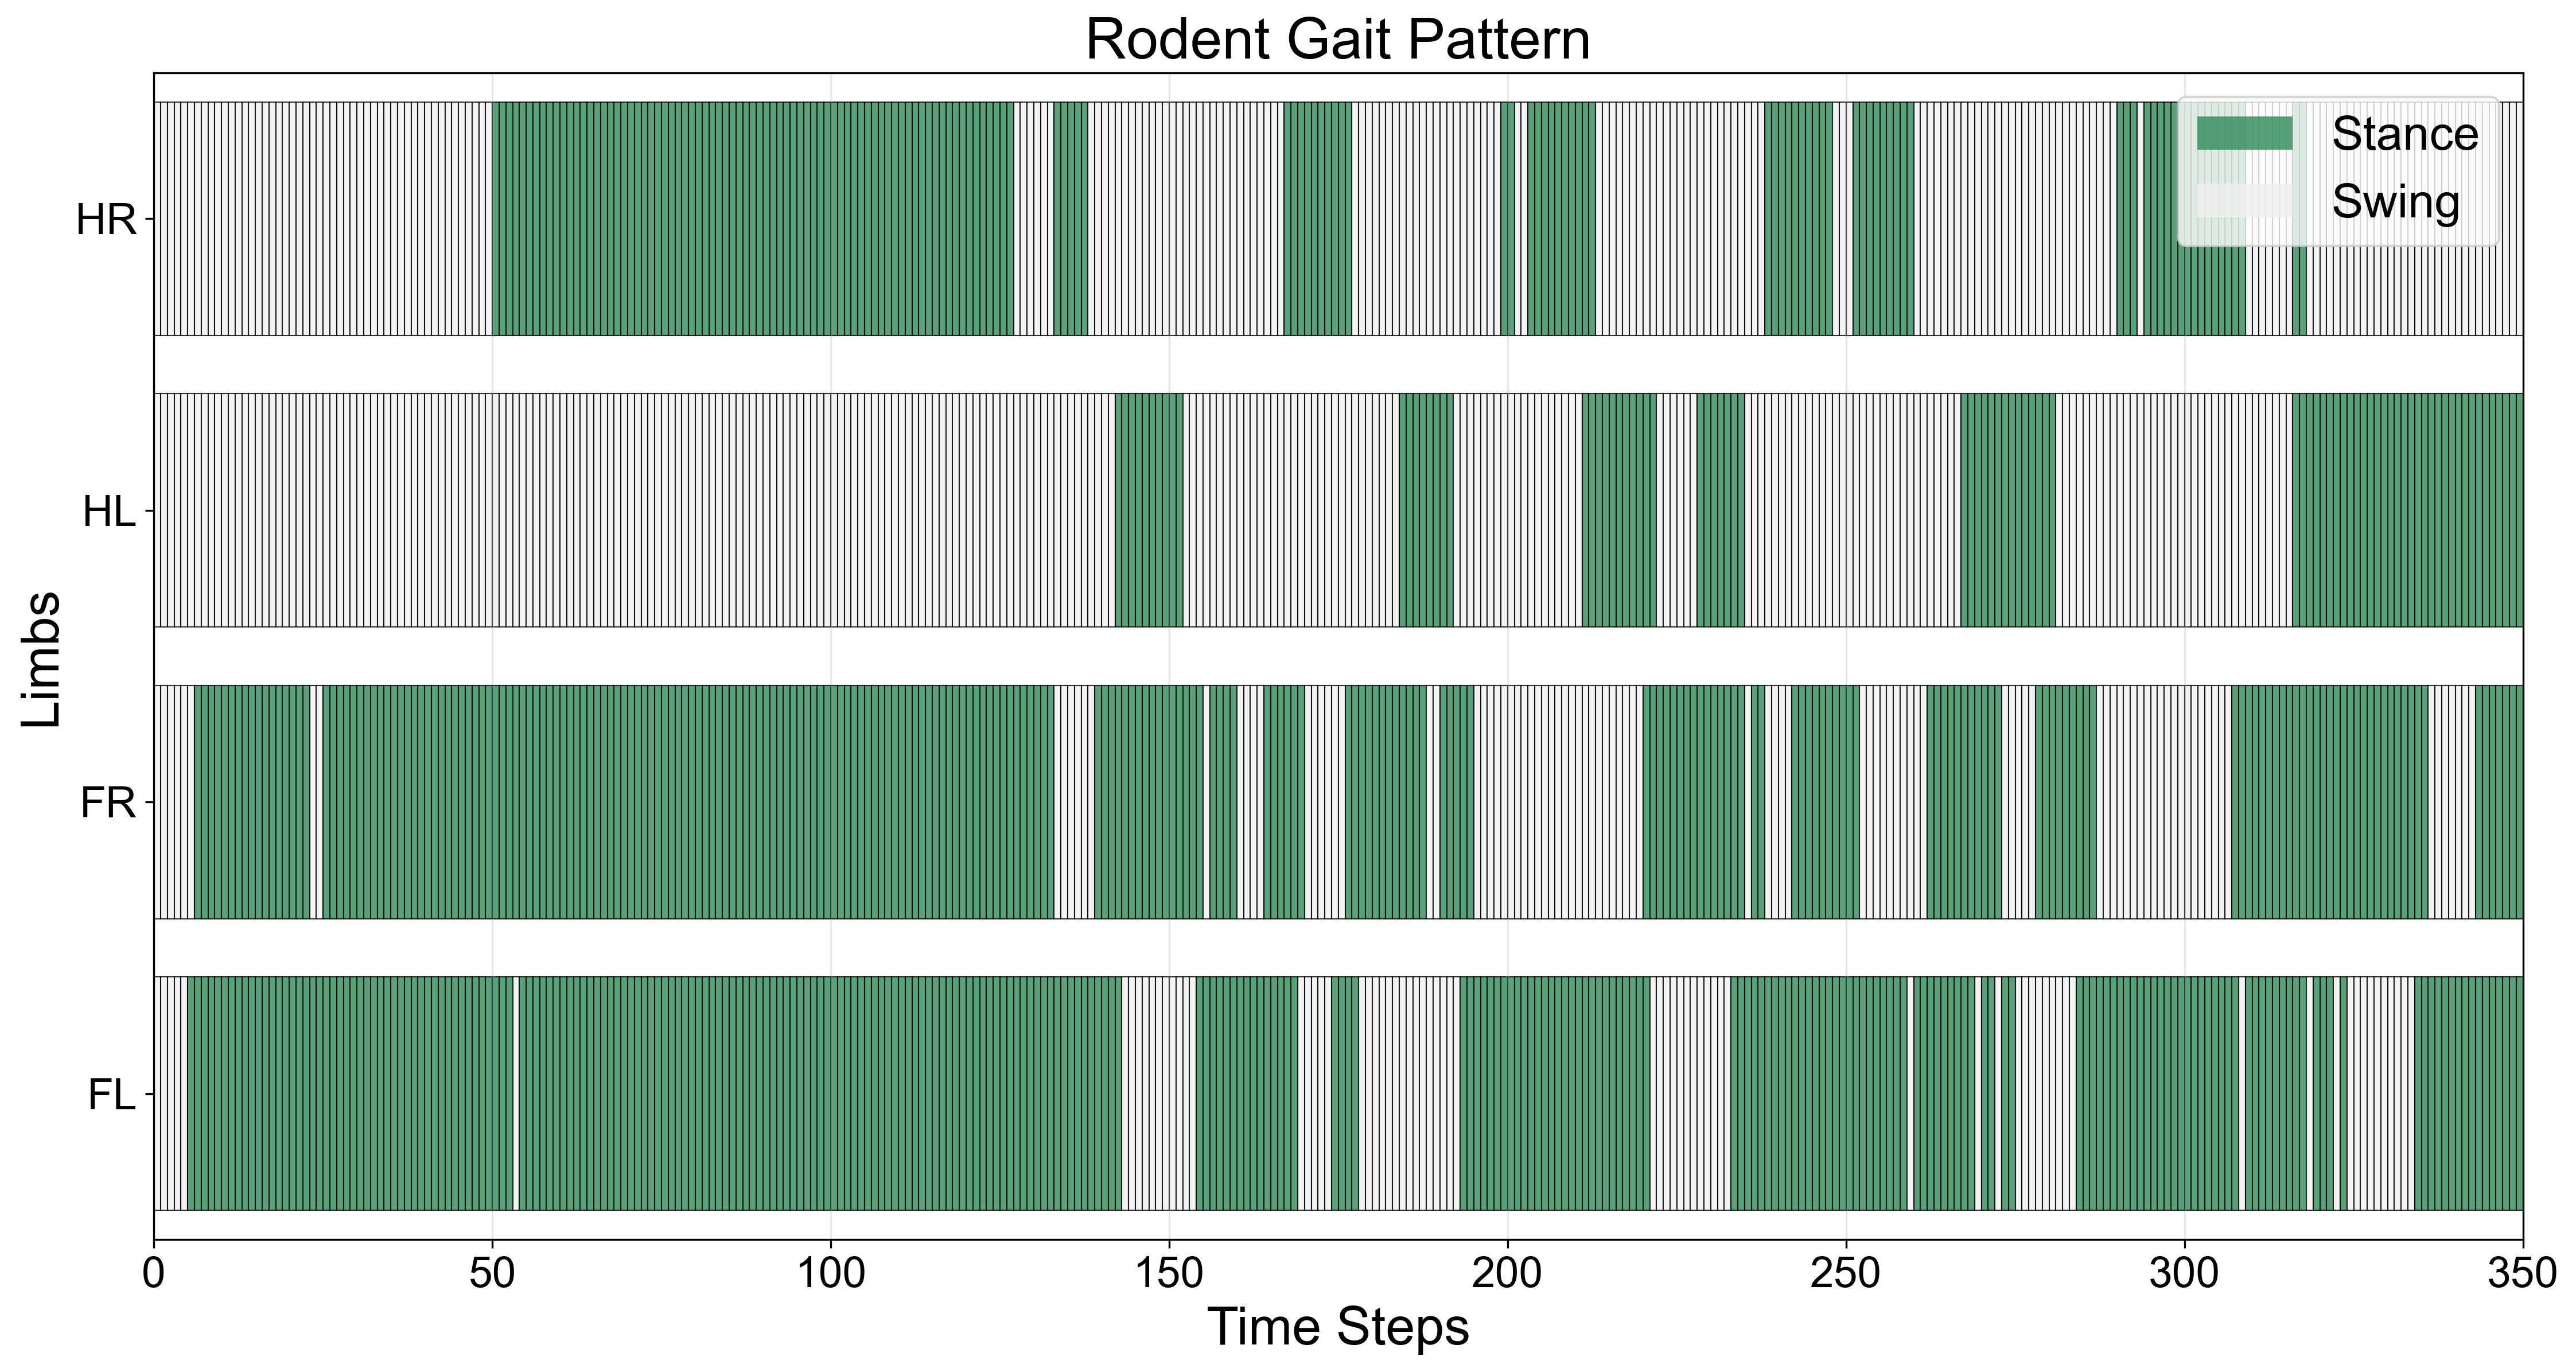

In [20]:
clip = 13
start_time = 0
end_time = 350

plot_gait_diagram(
    all_contact_barcodes[clip][:, start_time:end_time],
    labels=["FL", "FR", "HL", "HR"],
    title="Rodent Gait Pattern",
    tick_fontsize=18,
    label_fontsize=22,
    legend_fontsize=20,
    title_fontsize=24,
)

### With smoothing

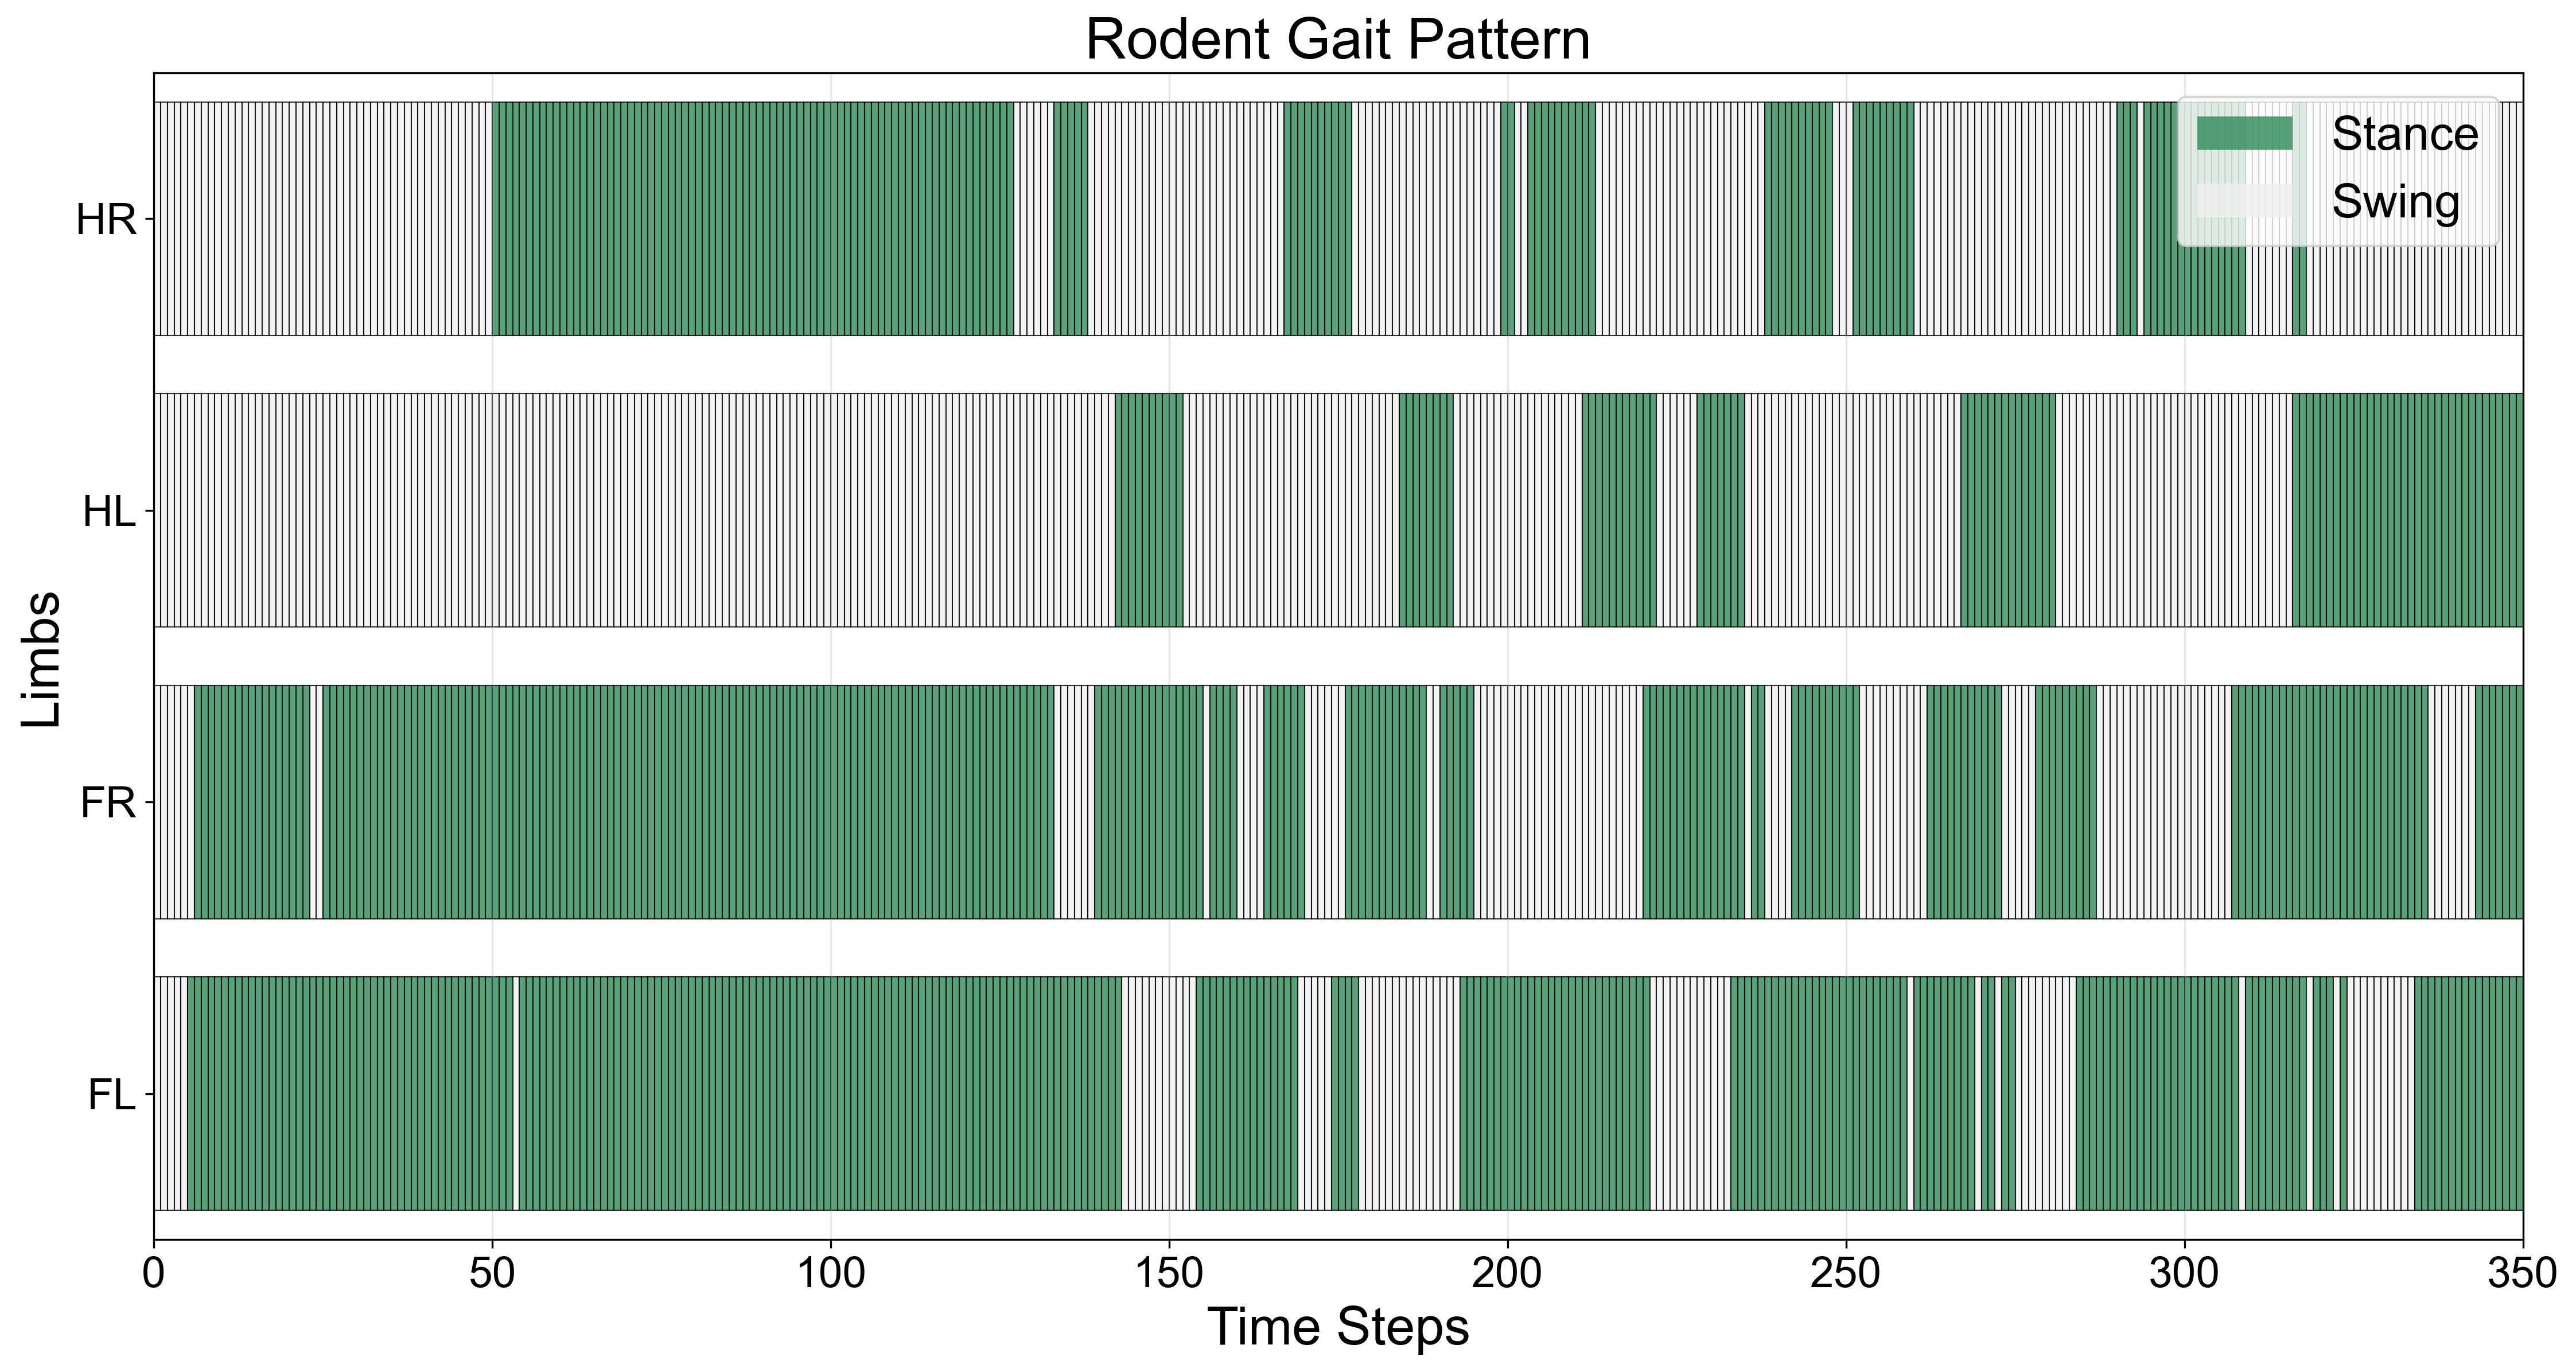

In [21]:
clip = 13
start_time = 0
end_time = 350
limb_index = 2

og_barcode = all_contact_barcodes[clip][:, :]
smooth_barcode = og_barcode.copy()

smoothed = medfilt(smooth_barcode[limb_index, :], kernel_size=11)
smooth_barcode[limb_index, :] = smoothed

plot_gait_diagram(
    smooth_barcode[:, start_time:end_time],
    labels=["FL", "FR", "HL", "HR"],
    title="Rodent Gait Pattern",
    tick_fontsize=18,
    label_fontsize=22,
    legend_fontsize=20,
    title_fontsize=24,
)

In [ ]:
from track_mjx.analysis import rollout, render, utils

rollouts = utils.load_from_h5py("/root/vast/scott-yang/data/best_rodent_ckpts/rollout_info_all_clips.h5")
single_rollout = jax.tree_util.tree_map(lambda x: x[clip_idxs[13]], rollouts)
frames, realtime_framerate = render.render_rollout(
    cfg,
    single_rollout,
    height=480,
    width=640,
)
media.show_video(frames, fps=50)

In [23]:
jit_vmap_out.pipeline_state.xpos.shape

(26, 500, 68, 3)

In [24]:
env.dt

Array(0.01, dtype=float32)

## Choose good clips

Here you must manually select which clips are good and the time windows from each clip that the analysis should take place over.

**Note**: many clips containing rearing behaviour, it is recommended you select a time window that only contains walking. 

**You can render the rollouts below to double check**

In [25]:
good_clips = [2, 5, 9, 13]
time_windows = [(150, 350), (100, 400), (100, 500), (0, 350)]

# Gait Cycle Analysis

### Gait selection + statistics

### ✨ New Gait Metrics Added

The `analyze_gait_cycles_data` function now calculates additional biomechanical metrics:

1. **Stride Length (mm)**: Calculated as the 3D Euclidean distance between the foot position at the start and end of each stride, using `pipeline_state.xpos` data.

2. **Velocity (cm/sec)**: Computed by dividing the stride length by the cycle duration. Uses dt=0.01 seconds between timesteps.

3. **Cadence (steps/min)**: Number of steps per minute, calculated from the gait cycle duration.

4. **Stance Percentage (%)**: Percentage of the gait cycle spent in stance phase, calculated from the contact trace with the same smoothing as used for gait cycle detection.

**New Parameter**: `foot_body_idx` - The body index for the foot corresponding to the limb used for gait cycle detection. This is used to extract position data for stride length and velocity calculations.

All metrics are stored in `results['gait_metrics']` with mean, std, and individual values for each cycle.

### Finding the foot body index

To calculate stride length and velocity, you need to provide the body index for the foot that corresponds to the limb used for gait cycle detection (`limb_index`):

- `limb_index=0` (FL - Front Left) → use front left foot body
- `limb_index=1` (FR - Front Right) → use front right foot body  
- `limb_index=2` (HL - Hind Left) → use hind left foot body
- `limb_index=3` (HR - Hind Right) → use hind right foot body

You can find the body indices by examining the MuJoCo model:

```python
# Get body names and indices from the model
xml_path = "/root/vast/scott-yang/track-mjx/track_mjx/environment/walker/assets/rodent/rodent.xml"
mj_model = mujoco.MjModel.from_xml_path(xml_path)

for i in range(mj_model.nbody):
    body_name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_BODY, i)
    print(f"Body {i}: {body_name}")
```

Look for body names like "foot", "paw", "ankle", etc. that correspond to the limb.

In [26]:
# Example: Find foot body indices for rodent model
xml_path = "/root/vast/scott-yang/track-mjx/track_mjx/environment/walker/assets/rodent/rodent.xml"
mj_model = mujoco.MjModel.from_xml_path(xml_path)

print("Body indices (look for foot/paw/ankle bodies):")
for i in range(mj_model.nbody):
    body_name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_BODY, i)
    if body_name and ('foot' in body_name.lower() or 'paw' in body_name.lower() or 
                       'ankle' in body_name.lower() or 'hand' in body_name.lower()):
        print(f"  Body {i}: {body_name}")

Body indices (look for foot/paw/ankle bodies):
  Body 13: foot_L
  Body 17: foot_R
  Body 61: hand_L
  Body 66: hand_R


In [27]:
def analyze_gait_cycles_data(
    all_contact_barcodes,
    jit_vmap_out,
    good_clips,
    qposes_ref,
    time_windows,
    qpos_indices,
    convert_to_degrees=True,
    limb_index=1,
    smooth_contacts=True,
    smooth_kernel_size=11,
    min_cycle_length=20,
    save_data=False,
    data_filename=None,
    foot_body_idx=None,
):
    """
    Analyze joint angles across gait cycles for multiple rollouts (data processing only).

    Args:
        all_contact_barcodes: List of contact barcodes, one per rollout (shape: [rollout][4, time])
        jit_vmap_out: Vectorized rollout output with pipeline_state.qpos and pipeline_state.xpos
        good_clips: List of indices for good clips (subsets of rollouts)
        qposes_ref: Reference joint positions for all rollouts
        time_windows: List of (start, end) tuples defining analysis windows for each rollout
        qpos_indices: List of qpos indices to analyze (corresponding to qpos features)
        convert_to_degrees: Whether to convert radians to degrees (default: True)
        limb_index: Which limb to use for metric calculations (FL=0, FR=1, HL=2, HR=3)
                   Note: Gait cycle detection always uses limb_index=1 (FR)
        smooth_contacts: Whether to apply median filtering to contact barcode (default: True)
        smooth_kernel_size: Kernel size for median filter (default: 11)
        min_cycle_length: Minimum length for a valid gait cycle (default: 20)
        save_data: Whether to save the analysis data to HDF5 (default: False)
        data_filename: Filename to save the data to (default: None). If save_data=True and data_filename=None,
                      will use default filename
        foot_body_idx: Body index for the foot used in gait cycle detection (for xpos extraction)
                      If None, will be automatically determined from limb_index

    Returns:
        dict: Analysis results containing gait cycle data and statistics for ALL qpos indices,
              plus gait metrics (stride length, velocity, cadence, stance percentage)
    """

    from scipy.signal import medfilt
    from scipy import ndimage

    # Mapping from limb_index to foot_body_idx
    # limb_index: 0=FL (Foot Left), 1=FR (Foot Right), 2=HL (Hand Left), 3=HR (Hand Right)
    limb_to_body_mapping = {
        0: 13,  # FL (Foot Left) -> foot_L
        1: 17,  # FR (Foot Right) -> foot_R
        2: 61,  # HL (Hand Left) -> hand_L
        3: 66,  # HR (Hand Right) -> hand_R
    }
    
    # Determine foot_body_idx based on limb_index if not explicitly provided
    if foot_body_idx is None:
        foot_body_idx = limb_to_body_mapping.get(limb_index)
        if foot_body_idx is None:
            print(f"Warning: Invalid limb_index {limb_index}. Metrics calculation will be skipped.")
    
    # Always use limb_index=1 (FR - Foot Right) for gait cycle detection
    gait_detection_limb_index = 1
    print(f"Using limb_index={gait_detection_limb_index} (FR - Foot Right) for gait cycle detection")
    print(f"Using limb_index={limb_index} with foot_body_idx={foot_body_idx} for metric calculations")

    contact_barcodes = [all_contact_barcodes[i] for i in good_clips]

    def find_gait_cycles(contact_barcode, start_time, end_time):
        """Find gait cycles based on gait_detection_limb_index stance phases within time window."""
        # Apply smoothing to the contact barcode if requested
        if smooth_contacts:
            # Create a copy to avoid modifying original data
            smooth_barcode = contact_barcode.copy().astype(float)

            # Apply median filter to the limb used for gait cycle detection
            smoothed_limb = medfilt(
                smooth_barcode[gait_detection_limb_index, :], kernel_size=smooth_kernel_size
            )

            # Apply morphological operations to clean up the signal further
            # Close small gaps, then open to remove small spikes
            structure = np.ones(3)
            closed = ndimage.binary_closing(smoothed_limb > 0.3, structure=structure)
            opened = ndimage.binary_opening(closed, structure=structure)

            contacts = opened[start_time:end_time].astype(int)
        else:
            contacts = contact_barcode[gait_detection_limb_index, start_time:end_time]

        # Find all stance onsets (transitions from 0 to 1)
        stance_onsets = []
        for i in range(1, len(contacts)):
            if contacts[i - 1] == 0 and contacts[i] == 1:
                stance_onsets.append(start_time + i)

        # Filter out stance onsets that are too close together (likely noise)
        filtered_onsets = []
        if len(stance_onsets) > 0:
            filtered_onsets.append(stance_onsets[0])

            for onset in stance_onsets[1:]:
                if onset - filtered_onsets[-1] >= min_cycle_length:
                    filtered_onsets.append(onset)

        # Create gait cycles from consecutive stance onsets
        gait_cycles = []
        for i in range(len(filtered_onsets) - 1):
            cycle_start = filtered_onsets[i]
            cycle_end = filtered_onsets[i + 1]
            cycle_length = cycle_end - cycle_start

            # Only keep cycles that meet minimum length requirement
            if cycle_length >= min_cycle_length:
                gait_cycles.append((cycle_start, cycle_end))

        return gait_cycles

    def normalize_to_gait_percentage(data, cycle_length):
        """Interpolate data to standard 100-point gait cycle percentage."""

        # Try cubic interpolation first, fall back to linear if it fails
        original_time = np.linspace(0, 100, cycle_length)
        target_time = np.linspace(0, 100, 100)

        try:
            # Try cubic interpolation
            interp_func = interpolate.interp1d(
                original_time,
                data,
                kind="cubic",
                bounds_error=False,
                fill_value="extrapolate",
            )
            return interp_func(target_time)
        except ValueError:
            # Fall back to linear interpolation if cubic fails
            interp_func = interpolate.interp1d(
                original_time,
                data,
                kind="linear",
                bounds_error=False,
                fill_value="extrapolate",
            )
            return interp_func(target_time)

    # Storage for all gait cycle data - analyze ALL qpos indices
    all_gait_data = {
        qpos_idx: {"rollout": [], "reference": []} for qpos_idx in qpos_indices
    }
    
    # Storage for gait metrics
    gait_metrics = {
        "stride_length_mm": [],
        "velocity_cm_per_sec": [],
        "cadence_steps_per_min": [],
        "stance_percentage": [],
    }

    # Environment dt is 0.01 seconds (10ms between each step)
    dt = 0.01  # seconds

    print(
        f"Analyzing {len(time_windows)} rollouts for {len(qpos_indices)} qpos indices..."
    )
    if smooth_contacts:
        print(
            f"  Applying median filter (kernel_size={smooth_kernel_size}) to limb {gait_detection_limb_index} contacts for cycle detection"
        )
        print(f"  Minimum gait cycle length: {min_cycle_length} timesteps")

    # Process each rollout
    for rollout_idx, (start_time, end_time) in enumerate(time_windows):
        print(
            f"Processing rollout {rollout_idx + 1}/{len(time_windows)} "
            f"(time window: {start_time}-{end_time})"
        )

        # Get contact barcode for this rollout
        contact_barcode = contact_barcodes[rollout_idx]

        # Find gait cycles in this rollout (with smoothing applied internally)
        gait_cycles = find_gait_cycles(contact_barcode, start_time, end_time)
        print(f"  Found {len(gait_cycles)} gait cycles")

        # Print the time windows of each gait cycle
        if len(gait_cycles) > 0:
            print("  Gait cycle time windows:")
            for i, (cycle_start, cycle_end) in enumerate(gait_cycles):
                cycle_length = cycle_end - cycle_start
                print(
                    f"    Cycle {i+1}: [{cycle_start}-{cycle_end}] (length: {cycle_length})"
                )
        else:
            print(f"  Warning: No gait cycles found in rollout {rollout_idx}")
            continue

        # Extract joint data for this rollout
        rollout_qpos = jit_vmap_out.pipeline_state.qpos[
            good_clips[rollout_idx]
        ]  # Shape: (time, features)
        reference_qpos = qposes_ref[good_clips[rollout_idx]]  # Shape: (time, features)
        
        # Extract xpos data for stride length calculation if foot_body_idx is provided
        if foot_body_idx is not None:
            rollout_xpos = jit_vmap_out.pipeline_state.xpos[
                good_clips[rollout_idx]
            ]  # Shape: (time, n_bodies, 3)

        # Process each gait cycle
        for cycle_start, cycle_end in gait_cycles:
            cycle_length = cycle_end - cycle_start
            
            # Calculate gait metrics for this cycle
            # 1. Stride Length (mm): Cartesian distance traveled by the foot
            if foot_body_idx is not None:
                foot_pos_start = rollout_xpos[cycle_start, foot_body_idx, :]  # (3,) - [x, y, z]
                foot_pos_end = rollout_xpos[cycle_end, foot_body_idx, :]  # (3,) - [x, y, z]
                # Calculate 3D Euclidean distance and convert from meters to mm
                stride_length_m = np.linalg.norm(foot_pos_end - foot_pos_start)
                stride_length_mm = stride_length_m * 1000.0  # meters to mm
                gait_metrics["stride_length_mm"].append(stride_length_mm)
                
                # 2. Velocity (cm/sec): stride length divided by cycle duration
                cycle_duration_sec = cycle_length * dt  # convert timesteps to seconds
                velocity_m_per_sec = stride_length_m / cycle_duration_sec
                velocity_cm_per_sec = velocity_m_per_sec * 100.0  # m/s to cm/s
                gait_metrics["velocity_cm_per_sec"].append(velocity_cm_per_sec)
                
                # 3. Cadence (steps/min): steps per minute
                # One gait cycle = one stride = 2 steps (if measuring from one leg)
                # But since we're measuring cycle-to-cycle of the same leg, that's one "stride"
                # Cadence is typically steps/min, so 1 cycle = 1 step for that limb
                steps_per_sec = 1.0 / cycle_duration_sec
                cadence_steps_per_min = steps_per_sec * 60.0
                gait_metrics["cadence_steps_per_min"].append(cadence_steps_per_min)
            
            # 4. Stance Percentage: percentage of time in contact during the cycle
            # Use limb_index for stance percentage calculation (flexible based on which limb is being analyzed)
            contacts_in_cycle = contact_barcode[limb_index, cycle_start:cycle_end]
            if smooth_contacts:
                # Use the same smoothing as for cycle detection
                smooth_contacts_cycle = contacts_in_cycle.copy().astype(float)
                smoothed_limb = medfilt(smooth_contacts_cycle, kernel_size=min(smooth_kernel_size, len(smooth_contacts_cycle)))
                structure = np.ones(3)
                closed = ndimage.binary_closing(smoothed_limb > 0.3, structure=structure)
                opened = ndimage.binary_opening(closed, structure=structure)
                contacts_in_cycle = opened.astype(int)
            
            stance_frames = np.sum(contacts_in_cycle)
            stance_percentage = (stance_frames / cycle_length) * 100.0
            gait_metrics["stance_percentage"].append(stance_percentage)

            # Extract joint angles for ALL requested joints
            for qpos_idx in qpos_indices:
                # Extract rollout joint data for this cycle
                rollout_joint = rollout_qpos[cycle_start:cycle_end, qpos_idx]
                reference_joint = reference_qpos[cycle_start:cycle_end, qpos_idx]

                # Normalize to gait percentage (0-100%)
                rollout_normalized = normalize_to_gait_percentage(
                    rollout_joint, cycle_length
                )
                reference_normalized = normalize_to_gait_percentage(
                    reference_joint, cycle_length
                )

                # Store normalized data
                all_gait_data[qpos_idx]["rollout"].append(rollout_normalized)
                all_gait_data[qpos_idx]["reference"].append(reference_normalized)

    # Calculate statistics for ALL joints
    results = {}

    for qpos_idx in qpos_indices:
        rollout_cycles = np.array(all_gait_data[qpos_idx]["rollout"])
        reference_cycles = np.array(all_gait_data[qpos_idx]["reference"])

        if len(rollout_cycles) == 0:
            print(f"  Warning: No data found for qpos {qpos_idx}")
            continue

        # Calculate statistics with optional degree conversion
        if convert_to_degrees:
            rollout_mean = np.degrees(np.mean(rollout_cycles, axis=0))
            rollout_std = np.degrees(np.std(rollout_cycles, axis=0))
            reference_mean = np.degrees(np.mean(reference_cycles, axis=0))
            reference_std = np.degrees(np.std(reference_cycles, axis=0))

            # Store results (converted to degrees)
            results[qpos_idx] = {
                "rollout_mean": rollout_mean,
                "rollout_std": rollout_std,
                "reference_mean": reference_mean,
                "reference_std": reference_std,
                "n_cycles": len(rollout_cycles),
                "raw_cycles": {
                    "rollout": np.degrees(rollout_cycles),
                    "reference": np.degrees(reference_cycles),
                },
                "units": "°",
            }
        else:
            rollout_mean = np.mean(rollout_cycles, axis=0)
            rollout_std = np.std(rollout_cycles, axis=0)
            reference_mean = np.mean(reference_cycles, axis=0)
            reference_std = np.std(reference_cycles, axis=0)

            # Store results (in radians)
            results[qpos_idx] = {
                "rollout_mean": rollout_mean,
                "rollout_std": rollout_std,
                "reference_mean": reference_mean,
                "reference_std": reference_std,
                "n_cycles": len(rollout_cycles),
                "raw_cycles": {
                    "rollout": rollout_cycles,
                    "reference": reference_cycles,
                },
                "units": "rad",
            }

        # Print summary statistics
        print(f"  Qpos {qpos_idx}: {len(rollout_cycles)} gait cycles analyzed")

    print(
        f"\nAnalysis complete! Processed {sum(len(all_gait_data[j]['rollout']) for j in qpos_indices)} total gait cycles"
    )
    print(f"Results available for qpos indices: {list(results.keys())}")
    
    # Add gait metrics to results
    if len(gait_metrics["stride_length_mm"]) > 0:
        results["gait_metrics"] = {
            "stride_length_mm": {
                "mean": np.mean(gait_metrics["stride_length_mm"]),
                "std": np.std(gait_metrics["stride_length_mm"]),
                "all_values": np.array(gait_metrics["stride_length_mm"]),
                "n_cycles": len(gait_metrics["stride_length_mm"]),
            },
            "velocity_cm_per_sec": {
                "mean": np.mean(gait_metrics["velocity_cm_per_sec"]),
                "std": np.std(gait_metrics["velocity_cm_per_sec"]),
                "all_values": np.array(gait_metrics["velocity_cm_per_sec"]),
                "n_cycles": len(gait_metrics["velocity_cm_per_sec"]),
            },
            "cadence_steps_per_min": {
                "mean": np.mean(gait_metrics["cadence_steps_per_min"]),
                "std": np.std(gait_metrics["cadence_steps_per_min"]),
                "all_values": np.array(gait_metrics["cadence_steps_per_min"]),
                "n_cycles": len(gait_metrics["cadence_steps_per_min"]),
            },
            "stance_percentage": {
                "mean": np.mean(gait_metrics["stance_percentage"]),
                "std": np.std(gait_metrics["stance_percentage"]),
                "all_values": np.array(gait_metrics["stance_percentage"]),
                "n_cycles": len(gait_metrics["stance_percentage"]),
            },
        }
        
        print("\nGait Metrics Summary:")
        print(f"  Stride Length: {results['gait_metrics']['stride_length_mm']['mean']:.2f} ± {results['gait_metrics']['stride_length_mm']['std']:.2f} mm")
        print(f"  Velocity: {results['gait_metrics']['velocity_cm_per_sec']['mean']:.2f} ± {results['gait_metrics']['velocity_cm_per_sec']['std']:.2f} cm/sec")
        print(f"  Cadence: {results['gait_metrics']['cadence_steps_per_min']['mean']:.2f} ± {results['gait_metrics']['cadence_steps_per_min']['std']:.2f} steps/min")
        print(f"  Stance Percentage: {results['gait_metrics']['stance_percentage']['mean']:.2f} ± {results['gait_metrics']['stance_percentage']['std']:.2f} %")

    # Save analysis data if requested
    if save_data:
        from track_mjx.analysis.utils import save_to_h5py
        
        if data_filename is None:
            # Generate default filename using qpos indices
            qpos_str = "_".join(map(str, qpos_indices))
            data_filename = f"./figures/fig6/gait_analysis_full_{qpos_str}.h5"
        
        # Aggregate data for saving
        analysis_data_to_save = {
            "metadata": {
                "qpos_indices": np.array(qpos_indices),
                "good_clips": np.array(good_clips),
                "time_windows": np.array(time_windows),
                "limb_index": np.array([limb_index]),
                "gait_detection_limb_index": np.array([gait_detection_limb_index]),
                "foot_body_idx": np.array([foot_body_idx]) if foot_body_idx is not None else np.array([-1]),
                "smooth_contacts": np.array([smooth_contacts]),
                "smooth_kernel_size": np.array([smooth_kernel_size]),
                "min_cycle_length": np.array([min_cycle_length]),
                "convert_to_degrees": np.array([convert_to_degrees]),
                "units": results[qpos_indices[0]]["units"] if qpos_indices[0] in results else "°",
                "gait_percentage": np.linspace(0, 100, 100),
            },
            "results": {},
            "all_gait_data": {},
        }
        
        # Add computed results for each qpos index
        for qpos_idx in qpos_indices:
            if qpos_idx in results:
                result = results[qpos_idx]
                qpos_key = f"qpos_{qpos_idx}"
                analysis_data_to_save["results"][qpos_key] = {
                    "rollout_mean": result["rollout_mean"],
                    "rollout_std": result["rollout_std"],
                    "reference_mean": result["reference_mean"],
                    "reference_std": result["reference_std"],
                    "n_cycles": np.array([result["n_cycles"]]),
                    "rollout_cycles": result["raw_cycles"]["rollout"],
                    "reference_cycles": result["raw_cycles"]["reference"],
                }
        
        # Add gait metrics if available
        if "gait_metrics" in results:
            analysis_data_to_save["gait_metrics"] = {}
            for metric_name, metric_data in results["gait_metrics"].items():
                analysis_data_to_save["gait_metrics"][metric_name] = {
                    "mean": np.array([metric_data["mean"]]),
                    "std": np.array([metric_data["std"]]),
                    "all_values": metric_data["all_values"],
                    "n_cycles": np.array([metric_data["n_cycles"]]),
                }
        
        # Add raw gait cycle data (all individual cycles before aggregation)
        for qpos_idx in qpos_indices:
            if len(all_gait_data[qpos_idx]["rollout"]) > 0:
                qpos_key = f"qpos_{qpos_idx}"
                analysis_data_to_save["all_gait_data"][qpos_key] = {
                    "rollout_cycles": np.array(all_gait_data[qpos_idx]["rollout"]),
                    "reference_cycles": np.array(all_gait_data[qpos_idx]["reference"]),
                }
        
        save_to_h5py(data_filename, analysis_data_to_save)
        print(f"\nGait analysis data (results + raw cycles) saved to: {data_filename}")

    return results

### Example: Load complete analysis data

### Gait cycle plotting function

In [28]:
from track_mjx.analysis.utils import save_to_h5py

def plot_gait_cycles_stacked(
    results,
    qpos_indices_to_plot,
    figsize=(3, 3),
    rollout_color="blue",
    rollout_shade_alpha=0.2,
    reference_color="red",
    reference_shade_alpha=0.2,
    plot_titles=None,
    tick_fontsize=8,
    label_fontsize=8,
    legend_fontsize=8,
    save=False,
    filename=None,
    save_data=False,
    data_filename=None,
):
    """
    Plot gait cycle analysis results as stacked subplots.

    Args:
        results: Dictionary of analysis results from analyze_gait_cycles_data (contains ALL analyzed qpos)
        qpos_indices_to_plot: List of qpos indices to plot (subset of what was analyzed)
        figsize: Figure size for the entire plot
        rollout_color: Color for rollout line and shading (default: 'blue')
        rollout_shade_alpha: Alpha for rollout shading (default: 0.2)
        reference_color: Color for reference line and shading (default: 'red')
        reference_shade_alpha: Alpha for reference shading (default: 0.2)
        plot_titles: List of strings for plot titles, one per joint (default: None)
        tick_fontsize: Font size for axis tick labels (default: 14)
        label_fontsize: Font size for axis labels (default: 12)
        legend_fontsize: Font size for legend (default: 10)
        save: Whether to save the figure (default: False)
        filename: Filename to save the figure to (default: None). If save=True and filename=None,
                 will use default filename with qpos indices
        save_data: Whether to save the gait analysis data to HDF5 (default: False)
        data_filename: Filename to save the data to (default: None). If save_data=True and data_filename=None,
                      will use default filename with qpos indices
    """

    # Create stacked subplots for selected joints
    num_joints = len(qpos_indices_to_plot)
    fig, axes = plt.subplots(num_joints, 1, figsize=figsize, sharex=True)

    # Handle case where there's only one subplot
    if num_joints == 1:
        axes = [axes]

    gait_percentage = np.linspace(0, 100, 100)

    # Determine units from first result that exists
    units = "°"
    for qpos_idx in qpos_indices_to_plot:
        if qpos_idx in results:
            units = results[qpos_idx]["units"]
            break

    angle_unit = "°" if units == "°" else " rad"

    for i, qpos_idx in enumerate(qpos_indices_to_plot):
        if qpos_idx not in results:
            print(
                f"Warning: No results found for qpos {qpos_idx}. Available indices: {list(results.keys())}"
            )
            continue

        print(f"\nGenerating plot for qpos {qpos_idx}")
        ax = axes[i]

        result = results[qpos_idx]
        rollout_mean = result["rollout_mean"]
        rollout_std = result["rollout_std"]
        reference_mean = result["reference_mean"]
        reference_std = result["reference_std"]

        # Plot reference data first
        ax.plot(
            gait_percentage,
            reference_mean,
            color=reference_color,
            linewidth=2,
            label="STAC Registration",
        )
        ax.fill_between(
            gait_percentage,
            reference_mean - reference_std,
            reference_mean + reference_std,
            color=reference_color,
            alpha=reference_shade_alpha,
        )

        # Plot rollout data
        ax.plot(
            gait_percentage,
            rollout_mean,
            color=rollout_color,
            linewidth=2,
            label="Track Replay",
        )
        ax.fill_between(
            gait_percentage,
            rollout_mean - rollout_std,
            rollout_mean + rollout_std,
            color=rollout_color,
            alpha=rollout_shade_alpha,
        )

        # Determine subplot title/ylabel
        if plot_titles is not None and i < len(plot_titles):
            joint_label = plot_titles[i]
        else:
            joint_label = f"Qpos {qpos_idx}"

        # Set y-axis label for each subplot
        ax.set_ylabel(joint_label, fontsize=label_fontsize)

        # Remove grid
        ax.grid(False)

        # Remove legends from all subplots
        if ax.get_legend():
            ax.get_legend().remove()

        ax.tick_params(axis="both", which="major", labelsize=tick_fontsize)

        # For all but the last subplot: remove bottom spine and x-axis ticks
        if i < num_joints - 1:
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.spines["bottom"].set_visible(False)
            ax.tick_params(bottom=False, labelbottom=False)
            # Add gap at left spine
            ax.spines["left"].set_position(("outward", 1))
        else:
            # For the last subplot: keep bottom spine and x-axis
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            # Set x-axis spine bounds
            ax.spines["bottom"].set_bounds(0, 100)
            # Add gaps between spines
            ax.spines["left"].set_position(("outward", 1))
            ax.spines["bottom"].set_position(("outward", 3))

    # Add shared y-axis label with appropriate unit
    y_label = f"Joint Angle ({angle_unit})" if units == "°" else "Joint Angle (rad)"
    fig.text(
        -0.02,
        0.5,
        y_label,
        va="center",
        rotation="vertical",
        fontsize=8,
        fontweight="bold",
    )

    # Add manual legend at the upper right with vertical stacking
    legend_elements = [
        plt.Line2D([0], [0], color=reference_color, lw=2, label="STAC Registration"),
        plt.Line2D([0], [0], color=rollout_color, lw=2, label="Track Replay"),
    ]
    fig.legend(
        handles=legend_elements,
        loc="upper right",
        ncol=1,
        fontsize=legend_fontsize,
        frameon=False,
        bbox_to_anchor=(0.98, 1.05),
    )

    # Set x-axis label only on bottom subplot
    axes[-1].set_xlabel("Gait Cycle (%)", fontsize=8)

    # Adjust layout to accommodate shared y-label and legend
    plt.subplots_adjust(left=0.12, top=0.88)
    plt.tight_layout()

    # Save figure if requested
    if save:
        if filename is None:
            # Generate default filename using qpos indices
            qpos_str = "_".join(map(str, qpos_indices_to_plot))
            filename = f"./figures/fig6/gait_cycles_{qpos_str}.pdf"

        plt.savefig(
            filename,
            bbox_inches="tight",
            dpi=600,
        )
        print(f"Figure saved to: {filename}")

    # Save gait analysis data if requested
    if save_data:
        if data_filename is None:
            # Generate default filename using qpos indices
            qpos_str = "_".join(map(str, qpos_indices_to_plot))
            data_filename = f"./figures/fig6/gait_cycles_data_{qpos_str}.h5"
        
        # Aggregate data for saving
        gait_data_to_save = {
            "metadata": {
                "qpos_indices": np.array(qpos_indices_to_plot),
                "plot_titles": np.array(plot_titles) if plot_titles is not None else np.array([f"Qpos {i}" for i in qpos_indices_to_plot]),
                "gait_percentage": np.linspace(0, 100, 100),
                "units": results[qpos_indices_to_plot[0]]["units"] if qpos_indices_to_plot[0] in results else "°",
            }
        }
        
        # Add data for each qpos index
        for qpos_idx in qpos_indices_to_plot:
            if qpos_idx in results:
                result = results[qpos_idx]
                qpos_key = f"qpos_{qpos_idx}"
                gait_data_to_save[qpos_key] = {
                    "rollout_mean": result["rollout_mean"],
                    "rollout_std": result["rollout_std"],
                    "reference_mean": result["reference_mean"],
                    "reference_std": result["reference_std"],
                    "n_cycles": np.array([result["n_cycles"]]),
                    "rollout_cycles": result["raw_cycles"]["rollout"],
                    "reference_cycles": result["raw_cycles"]["reference"],
                }
        
        save_to_h5py(data_filename, gait_data_to_save)
        print(f"Gait analysis data saved to: {data_filename}")

    plt.show()

In [29]:
from track_mjx.analysis.utils import load_from_h5py

def load_and_plot_gait_data(
    data_filename,
    figsize=(3, 3),
    rollout_color="blue",
    rollout_shade_alpha=0.2,
    reference_color="red",
    reference_shade_alpha=0.2,
    tick_fontsize=8,
    label_fontsize=8,
    legend_fontsize=8,
):
    """
    Load gait analysis data from HDF5 file and plot it.
    
    Args:
        data_filename: Path to the HDF5 file containing gait analysis data
        figsize: Figure size for the entire plot
        rollout_color: Color for rollout line and shading (default: 'blue')
        rollout_shade_alpha: Alpha for rollout shading (default: 0.2)
        reference_color: Color for reference line and shading (default: 'red')
        reference_shade_alpha: Alpha for reference shading (default: 0.2)
        tick_fontsize: Font size for axis tick labels (default: 8)
        label_fontsize: Font size for axis labels (default: 8)
        legend_fontsize: Font size for legend (default: 8)
    
    Returns:
        dict: Loaded gait analysis data
    """
    # Load data from HDF5
    gait_data = load_from_h5py(data_filename)
    print(f"Loaded gait analysis data from: {data_filename}")
    
    # Extract metadata
    qpos_indices = gait_data["metadata"]["qpos_indices"].tolist()
    plot_titles = gait_data["metadata"]["plot_titles"].tolist()
    gait_percentage = gait_data["metadata"]["gait_percentage"]
    units = gait_data["metadata"]["units"]
    
    # Create stacked subplots
    num_joints = len(qpos_indices)
    fig, axes = plt.subplots(num_joints, 1, figsize=figsize, sharex=True)
    
    # Handle case where there's only one subplot
    if num_joints == 1:
        axes = [axes]
    
    angle_unit = "°" if units == "°" else " rad"
    
    for i, qpos_idx in enumerate(qpos_indices):
        ax = axes[i]
        qpos_key = f"qpos_{qpos_idx}"
        
        if qpos_key not in gait_data:
            print(f"Warning: No data found for qpos {qpos_idx}")
            continue
        
        result = gait_data[qpos_key]
        rollout_mean = result["rollout_mean"]
        rollout_std = result["rollout_std"]
        reference_mean = result["reference_mean"]
        reference_std = result["reference_std"]
        
        # Plot reference data first
        ax.plot(
            gait_percentage,
            reference_mean,
            color=reference_color,
            linewidth=2,
            label="STAC Registration",
        )
        ax.fill_between(
            gait_percentage,
            reference_mean - reference_std,
            reference_mean + reference_std,
            color=reference_color,
            alpha=reference_shade_alpha,
        )
        
        # Plot rollout data
        ax.plot(
            gait_percentage,
            rollout_mean,
            color=rollout_color,
            linewidth=2,
            label="Track Replay",
        )
        ax.fill_between(
            gait_percentage,
            rollout_mean - rollout_std,
            rollout_mean + rollout_std,
            color=rollout_color,
            alpha=rollout_shade_alpha,
        )
        
        # Set y-axis label
        joint_label = plot_titles[i] if isinstance(plot_titles[i], str) else plot_titles[i].decode('utf-8')
        ax.set_ylabel(joint_label, fontsize=label_fontsize)
        
        # Remove grid
        ax.grid(False)
        
        # Remove legends from all subplots
        if ax.get_legend():
            ax.get_legend().remove()
        
        ax.tick_params(axis="both", which="major", labelsize=tick_fontsize)
        
        # For all but the last subplot: remove bottom spine and x-axis ticks
        if i < num_joints - 1:
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.spines["bottom"].set_visible(False)
            ax.tick_params(bottom=False, labelbottom=False)
            ax.spines["left"].set_position(("outward", 1))
        else:
            # For the last subplot: keep bottom spine and x-axis
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.spines["bottom"].set_bounds(0, 100)
            ax.spines["left"].set_position(("outward", 1))
            ax.spines["bottom"].set_position(("outward", 3))
    
    # Add shared y-axis label
    y_label = f"Joint Angle ({angle_unit})" if units == "°" else "Joint Angle (rad)"
    fig.text(
        -0.02,
        0.5,
        y_label,
        va="center",
        rotation="vertical",
        fontsize=8,
        fontweight="bold",
    )
    
    # Add manual legend at the upper right
    legend_elements = [
        plt.Line2D([0], [0], color=reference_color, lw=2, label="STAC Registration"),
        plt.Line2D([0], [0], color=rollout_color, lw=2, label="Track Replay"),
    ]
    fig.legend(
        handles=legend_elements,
        loc="upper right",
        ncol=1,
        fontsize=legend_fontsize,
        frameon=False,
        bbox_to_anchor=(0.98, 1.05),
    )
    
    # Set x-axis label only on bottom subplot
    axes[-1].set_xlabel("Gait Cycle (%)", fontsize=8)
    
    # Adjust layout
    plt.subplots_adjust(left=0.12, top=0.88)
    plt.tight_layout()
    plt.show()
    
    return gait_data

# Actual Plotting and Analysis

### Example: Save and load gait data

**Body Index Mapping for Rodent Model:**
- `limb_index=0` (FL - Foot Left) → `foot_body_idx=13` (foot_L)
- `limb_index=1` (FR - Foot Right) →  `foot_body_idx=17` (foot_R)
- `limb_index=2` (HL - Hand Left) → `foot_body_idx=61` (hand_L)
- `limb_index=3` (HR - Hand Right) → `foot_body_idx=66` (hand_R)

In [31]:
# Analyze ALL qpos indices of interest
all_qpos_indices = [
    15,
    21,
    16,
    22,
    17,
    23,
    61,
    69,
    63,
    71,
]  # Include all joints you might want to plot

good_clips = [2, 5, 9, 13]
time_windows = [(150, 350), (100, 400), (100, 500), (135, 350)]

results = analyze_gait_cycles_data(
    all_contact_barcodes,
    jit_vmap_out,
    good_clips,
    qposes_ref,
    time_windows,
    all_qpos_indices,
    convert_to_degrees=True,
    limb_index=1,  # Which limb to use for metric calculations (gait cycle detection always uses limb_index=1)
    smooth_kernel_size=11,
    min_cycle_length=20,
    save_data=False,  # Enable saving analysis data
    data_filename="./../data/gait_analysis_complete.h5",  # Optional: specify filename
    # foot_body_idx will be automatically determined from limb_index if not provided
    # foot_body_idx=17,  # Explicitly set if needed: 13=foot_L, 17=foot_R, 61=hand_L, 66=hand_R
)

Using limb_index=1 (FR - Foot Right) for gait cycle detection
Using limb_index=1 with foot_body_idx=17 for metric calculations
Analyzing 4 rollouts for 10 qpos indices...
  Applying median filter (kernel_size=11) to limb 1 contacts for cycle detection
  Minimum gait cycle length: 20 timesteps
Processing rollout 1/4 (time window: 150-350)
  Found 3 gait cycles
  Gait cycle time windows:
    Cycle 1: [181-215] (length: 34)
    Cycle 2: [215-249] (length: 34)
    Cycle 3: [249-294] (length: 45)
Processing rollout 2/4 (time window: 100-400)
  Found 5 gait cycles
  Gait cycle time windows:
    Cycle 1: [109-159] (length: 50)
    Cycle 2: [159-201] (length: 42)
    Cycle 3: [201-252] (length: 51)
    Cycle 4: [252-310] (length: 58)
    Cycle 5: [310-349] (length: 39)
Processing rollout 3/4 (time window: 100-500)
  Found 5 gait cycles
  Gait cycle time windows:
    Cycle 1: [149-217] (length: 68)
    Cycle 2: [217-283] (length: 66)
    Cycle 3: [283-339] (length: 56)
    Cycle 4: [339-409] (l

In [38]:
def render_gait_cycles(
    cfg,
    jit_vmap_out,
    all_contact_barcodes,
    good_clips,
    time_windows,
    limb_index=1,
    smooth_contacts=True,
    smooth_kernel_size=11,
    min_cycle_length=20,
    height=480,
    width=640,
    fps=50,
    save_videos=True,
    output_dir="./videos/gait_cycles/",
):
    """
    Render videos for each identified gait cycle.
    
    Args:
        cfg: Configuration dictionary
        jit_vmap_out: Vectorized rollout output with pipeline_state
        all_contact_barcodes: List of contact barcodes for all rollouts
        good_clips: List of indices for good clips
        time_windows: List of (start, end) tuples defining analysis windows
        limb_index: Which limb to use for gait cycle detection (default: 1 for FR)
        smooth_contacts: Whether to apply median filtering (default: True)
        smooth_kernel_size: Kernel size for median filter (default: 11)
        min_cycle_length: Minimum length for a valid gait cycle (default: 20)
        height: Video height in pixels (default: 480)
        width: Video width in pixels (default: 640)
        fps: Frames per second for video playback (default: 50)
        save_videos: Whether to save videos to disk (default: True)
        output_dir: Directory to save videos (default: "./videos/gait_cycles/")
    
    Returns:
        dict: Dictionary mapping (clip_idx, cycle_idx) to video frames
    """
    from scipy.signal import medfilt
    from scipy import ndimage
    from track_mjx.analysis import render
    import os
    
    # Create output directory if it doesn't exist
    if save_videos:
        os.makedirs(output_dir, exist_ok=True)
    
    def find_gait_cycles(contact_barcode, start_time, end_time):
        """Find gait cycles based on limb_index stance phases within time window."""
        if smooth_contacts:
            smooth_barcode = contact_barcode.copy().astype(float)
            smoothed_limb = medfilt(
                smooth_barcode[limb_index, :], kernel_size=smooth_kernel_size
            )
            structure = np.ones(3)
            closed = ndimage.binary_closing(smoothed_limb > 0.3, structure=structure)
            opened = ndimage.binary_opening(closed, structure=structure)
            contacts = opened[start_time:end_time].astype(int)
        else:
            contacts = contact_barcode[limb_index, start_time:end_time]
        
        # Find stance onsets
        stance_onsets = []
        for i in range(1, len(contacts)):
            if contacts[i - 1] == 0 and contacts[i] == 1:
                stance_onsets.append(start_time + i)
        
        # Filter onsets
        filtered_onsets = []
        if len(stance_onsets) > 0:
            filtered_onsets.append(stance_onsets[0])
            for onset in stance_onsets[1:]:
                if onset - filtered_onsets[-1] >= min_cycle_length:
                    filtered_onsets.append(onset)
        
        # Create gait cycles
        gait_cycles = []
        for i in range(len(filtered_onsets) - 1):
            cycle_start = filtered_onsets[i]
            cycle_end = filtered_onsets[i + 1]
            cycle_length = cycle_end - cycle_start
            if cycle_length >= min_cycle_length:
                gait_cycles.append((cycle_start, cycle_end))
        
        return gait_cycles
    
    contact_barcodes = [all_contact_barcodes[i] for i in good_clips]
    rendered_videos = {}
    
    print(f"Rendering gait cycle videos for {len(time_windows)} clips...")
    
    # Process each clip
    for clip_idx, (start_time, end_time) in enumerate(time_windows):
        print(f"\nProcessing clip {clip_idx + 1}/{len(time_windows)} (clip index: {good_clips[clip_idx]})")
        
        contact_barcode = contact_barcodes[clip_idx]
        gait_cycles = find_gait_cycles(contact_barcode, start_time, end_time)
        
        print(f"  Found {len(gait_cycles)} gait cycles")
        
        # Render each gait cycle
        for cycle_idx, (cycle_start, cycle_end) in enumerate(gait_cycles):
            print(f"    Rendering cycle {cycle_idx + 1}: frames [{cycle_start}-{cycle_end}]")
            
            # Extract pipeline state for this gait cycle
            qposes = jax.tree.map(
                lambda x: x[good_clips[clip_idx], cycle_start:cycle_end],
                jit_vmap_out.pipeline_state.qpos
            )

            frames, realtime_framerate = render.render_rollout(
                cfg,
                {"qposes_rollout": qposes},
                height=height,
                width=width,
                render_ghost=False
            )
            
            # Store frames
            key = (good_clips[clip_idx], cycle_idx)
            rendered_videos[key] = frames
            
            # Save video if requested
            if save_videos:
                video_filename = os.path.join(
                    output_dir,
                    f"clip_{good_clips[clip_idx]}_cycle_{cycle_idx}_frames_{cycle_start}-{cycle_end}.mp4"
                )
                media.write_video(video_filename, frames, fps=fps)
                print(f"      Saved: {video_filename}")
            
    print(f"\nRendering complete! Generated {len(rendered_videos)} videos")
    if save_videos:
        print(f"Videos saved to: {output_dir}")
    
    return rendered_videos


# Run the rendering for all gait cycles
rendered_gait_videos = render_gait_cycles(
    cfg=cfg,
    jit_vmap_out=jit_vmap_out,
    all_contact_barcodes=all_contact_barcodes,
    good_clips=good_clips,
    time_windows=time_windows,
    limb_index=1,  # FR - Front Right (same as used for gait cycle detection)
    smooth_contacts=True,
    smooth_kernel_size=11,
    min_cycle_length=20,
    height=480,
    width=640,
    fps=50,
    save_videos=True,
    output_dir="./videos/gait_cycles/",
)

Rendering gait cycle videos for 4 clips...

Processing clip 1/4 (clip index: 2)
  Found 3 gait cycles
    Rendering cycle 1: frames [181-215]
MuJoCo Rendering...
MuJoCo Rendering...


100%|██████████| 34/34 [00:00<00:00, 69.11it/s]



      Saved: ./videos/gait_cycles/clip_2_cycle_0_frames_181-215.mp4
    Rendering cycle 2: frames [215-249]
MuJoCo Rendering...
MuJoCo Rendering...


100%|██████████| 34/34 [00:00<00:00, 197.92it/s]



      Saved: ./videos/gait_cycles/clip_2_cycle_1_frames_215-249.mp4
    Rendering cycle 3: frames [249-294]
MuJoCo Rendering...
MuJoCo Rendering...


...

      Saved: ./videos/gait_cycles/clip_13_cycle_2_frames_220-262.mp4
    Rendering cycle 4: frames [262-307]
MuJoCo Rendering...
MuJoCo Rendering...


100%|██████████| 45/45 [00:00<00:00, 259.41it/s]



      Saved: ./videos/gait_cycles/clip_13_cycle_3_frames_262-307.mp4
    Rendering cycle 5: frames [307-343]
MuJoCo Rendering...
MuJoCo Rendering...


100%|██████████| 36/36 [00:00<00:00, 84.98it/s]



      Saved: ./videos/gait_cycles/clip_13_cycle_4_frames_307-343.mp4

Rendering complete! Generated 18 videos
Videos saved to: ./videos/gait_cycles/


### Display rendered gait cycle videos

You can review individual gait cycles by selecting the clip index and cycle number:

In [ ]:
# Example: Display a specific gait cycle video
# Change these values to view different cycles
clip_to_view = good_clips[0]  # First good clip
cycle_to_view = 0  # First cycle

if (clip_to_view, cycle_to_view) in rendered_gait_videos:
    frames = rendered_gait_videos[(clip_to_view, cycle_to_view)]
    print(f"Displaying clip {clip_to_view}, cycle {cycle_to_view}")
    print(f"Number of frames: {len(frames)}")
    print(f"Duration: {len(frames) * 0.02:.2f} seconds (at 50 fps)")
    media.show_video(frames, fps=50)
else:
    print(f"No video found for clip {clip_to_view}, cycle {cycle_to_view}")
    print(f"Available videos: {list(rendered_gait_videos.keys())}")

### Display all gait cycles as a grid

View all rendered gait cycles in a summary grid:

In [ ]:
# Display summary of all rendered gait cycles
print("Summary of rendered gait cycles:")
print("=" * 60)

for clip_idx in good_clips:
    cycle_count = sum(1 for (c, _) in rendered_gait_videos.keys() if c == clip_idx)
    if cycle_count > 0:
        print(f"\nClip {clip_idx}: {cycle_count} gait cycles")
        for cycle_idx in range(cycle_count):
            if (clip_idx, cycle_idx) in rendered_gait_videos:
                frames = rendered_gait_videos[(clip_idx, cycle_idx)]
                duration = len(frames) * 0.02  # dt = 0.01, but rendered at 50 fps = 0.02s per frame
                print(f"  Cycle {cycle_idx}: {len(frames)} frames ({duration:.2f}s)")

print("\n" + "=" * 60)
print(f"Total gait cycles rendered: {len(rendered_gait_videos)}")

# Optional: Create a montage showing first frame of each cycle
fig, axes = plt.subplots(len(good_clips), max(sum(1 for (c, _) in rendered_gait_videos.keys() if c == clip_idx) for clip_idx in good_clips), 
                         figsize=(15, 8))

if len(good_clips) == 1:
    axes = [axes]

for clip_row, clip_idx in enumerate(good_clips):
    cycle_count = sum(1 for (c, _) in rendered_gait_videos.keys() if c == clip_idx)
    
    for cycle_idx in range(cycle_count):
        if (clip_idx, cycle_idx) in rendered_gait_videos:
            frames = rendered_gait_videos[(clip_idx, cycle_idx)]
            
            # Show middle frame as thumbnail
            mid_frame_idx = len(frames) // 2
            
            if cycle_count == 1:
                ax = axes[clip_row]
            else:
                ax = axes[clip_row, cycle_idx] if len(good_clips) > 1 else axes[cycle_idx]
            
            ax.imshow(frames[mid_frame_idx])
            ax.set_title(f"Clip {clip_idx}\nCycle {cycle_idx}", fontsize=8)
            ax.axis('off')
    
    # Hide unused subplots
    max_cycles = max(sum(1 for (c, _) in rendered_gait_videos.keys() if c == clip_idx) for clip_idx in good_clips)
    for empty_idx in range(cycle_count, max_cycles):
        if cycle_count == 1:
            continue
        ax = axes[clip_row, empty_idx] if len(good_clips) > 1 else axes[empty_idx]
        ax.axis('off')

plt.tight_layout()
plt.suptitle("Gait Cycle Thumbnails (Middle Frame)", fontsize=12, y=1.02)
plt.show()

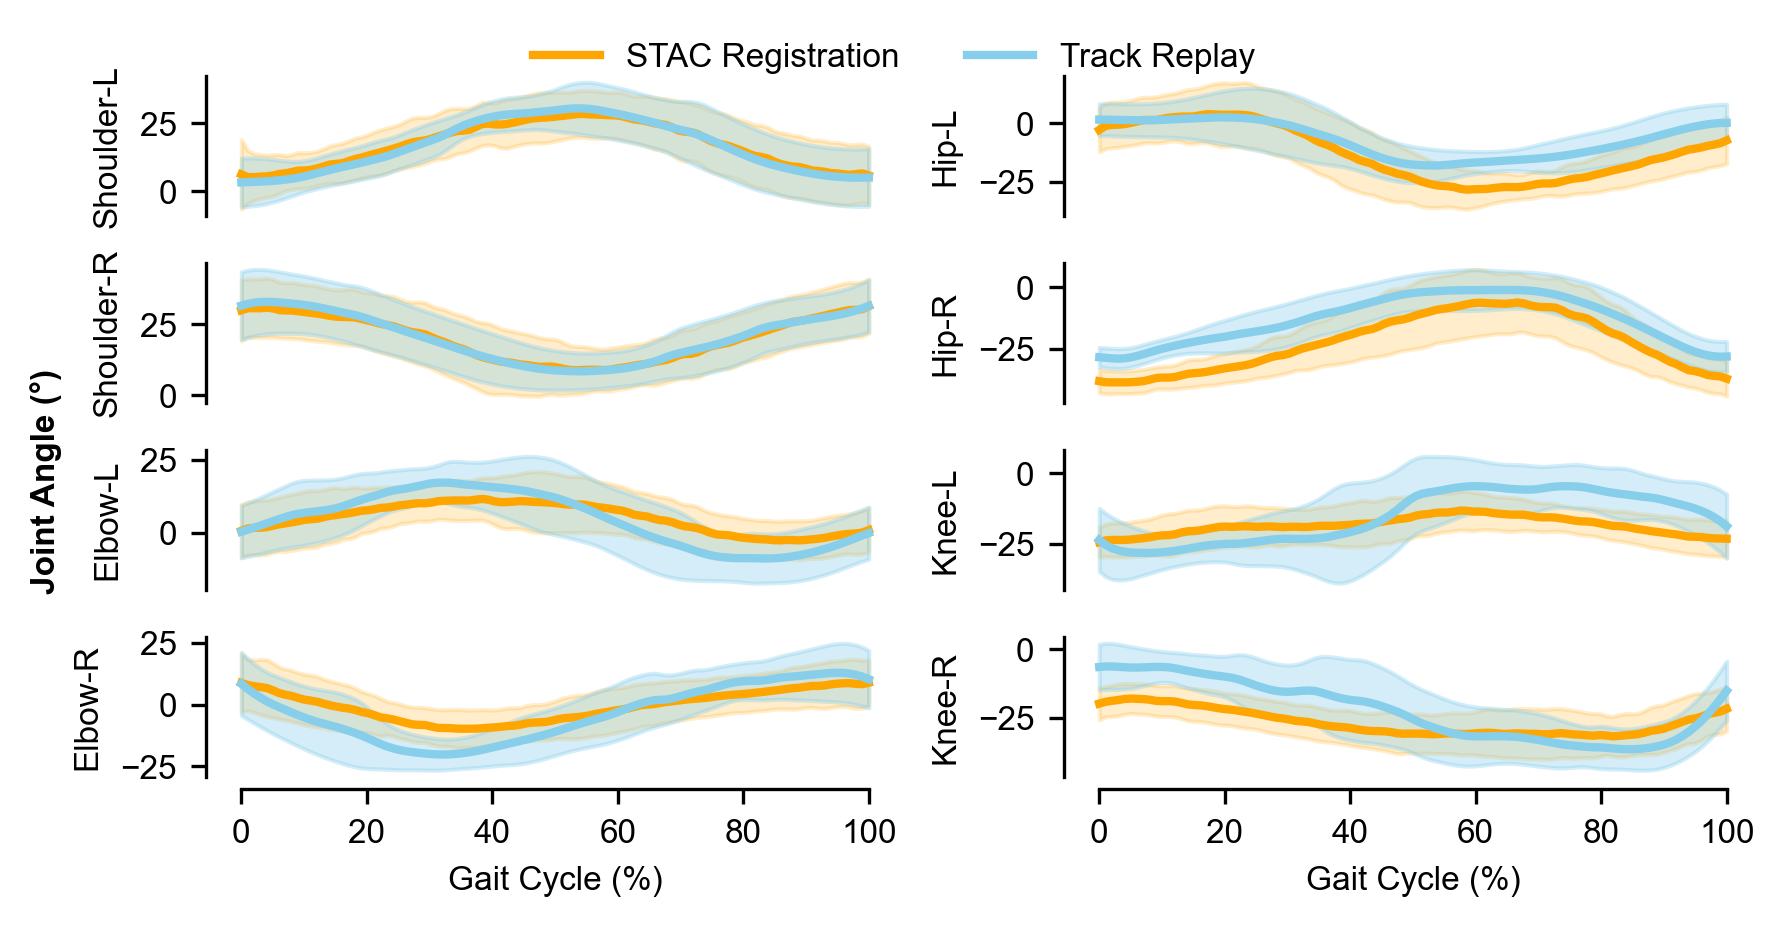

In [51]:
# Create a combined plot with 2 columns (forelimbs and hindlimbs)
forelimb_indices = [61, 69, 63, 71]
forelimb_titles = ["Shoulder-L", "Shoulder-R", "Elbow-L", "Elbow-R"]

hindlimb_indices = [15, 21, 16, 22]
hindlimb_titles = ["Hip-L", "Hip-R", "Knee-L", "Knee-R"]

# Combine all indices and titles for plotting
all_indices = [forelimb_indices, hindlimb_indices]
all_titles = [forelimb_titles, hindlimb_titles]

# Create figure with 2 columns, each with 4 rows
fig, axes = plt.subplots(4, 2, figsize=(6, 3), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = "#87CEEB"
rollout_shade_alpha = 0.35
reference_color = "#FFA500"
reference_shade_alpha = 0.2

# Plot each column
for col in range(2):
    joint_indices = all_indices[col]
    joint_titles = all_titles[col]
    
    for row, (qpos_idx, joint_title) in enumerate(zip(joint_indices, joint_titles)):
        ax = axes[row, col]
        
        if qpos_idx in results:
            result = results[qpos_idx]
            rollout_mean = result["rollout_mean"]
            rollout_std = result["rollout_std"]
            reference_mean = result["reference_mean"]
            reference_std = result["reference_std"]
            
            # Plot reference data
            ax.plot(
                gait_percentage,
                reference_mean,
                color=reference_color,
                linewidth=2,
                label="STAC Registration",
            )
            ax.fill_between(
                gait_percentage,
                reference_mean - reference_std,
                reference_mean + reference_std,
                color=reference_color,
                alpha=reference_shade_alpha,
            )
            
            # Plot rollout data
            ax.plot(
                gait_percentage,
                rollout_mean,
                color=rollout_color,
                linewidth=2,
                label="Track Replay",
            )
            ax.fill_between(
                gait_percentage,
                rollout_mean - rollout_std,
                rollout_mean + rollout_std,
                color=rollout_color,
                alpha=rollout_shade_alpha,
            )
        
        # Set y-axis label
        ax.set_ylabel(joint_title, fontsize=8)
        ax.grid(False)
        ax.tick_params(axis="both", which="major", labelsize=8)
        
        # Remove top and right spines
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        
        # For non-bottom rows: remove bottom spine and x-axis ticks
        if row < 3:
            ax.spines["bottom"].set_visible(False)
            ax.tick_params(bottom=False, labelbottom=False)
            ax.spines["left"].set_position(("outward", 1))
        else:
            # For bottom row: set spine bounds
            ax.spines["bottom"].set_bounds(0, 100)
            ax.spines["left"].set_position(("outward", 1))
            ax.spines["bottom"].set_position(("outward", 3))
            ax.set_xlabel("Gait Cycle (%)", fontsize=8)

# Add shared y-axis label
fig.text(
    0.02,
    0.5,
    "Joint Angle (°)",
    va="center",
    rotation="vertical",
    fontsize=8,
    fontweight="bold",
)

# Add legend
legend_elements = [
    plt.Line2D([0], [0], color=reference_color, lw=2, label="STAC Registration"),
    plt.Line2D([0], [0], color=rollout_color, lw=2, label="Track Replay"),
]
fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=2,
    fontsize=8,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)

plt.tight_layout()
plt.subplots_adjust(left=0.12, top=0.95)
plt.savefig(
    "./figures/fig2/gait_cycles_forelimbs_hindlimbs_batch.pdf",
    bbox_inches="tight",
    dpi=600,
)
plt.show()